<a href="https://colab.research.google.com/github/keyvanmahmoudi/Machine_Learning_Course/blob/main/solutions/Session14_final_project_solutions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# پاسخ تمرین‌های جلسهٔ ۱۴: پروژهٔ پایانی، پیش‌بینی پاسخ مشتری به تماس بازاریابی بانک

این نوت‌بوک پاسخ پیشنهادی تمرین‌های انتهای [نوت‌بوک جلسه](../sessions/Session14_final_project.ipynb) است. قبل از دیدن پاسخ‌ها، خودتان تمرین‌ها را حل کنید؛ معمولاً بیش از یک راه‌حل درست وجود دارد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### آماده‌سازی

داده، Pipeline و توابع کمکی پروژه را دوباره می‌سازیم. برای سرعت، به‌جای مدل تنظیم‌شده از HistGradientBoosting با ابرپارامترهای نزدیک به بهترین نتیجهٔ جلسه استفاده می‌کنیم.

</div>

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import average_precision_score
import seaborn as sns

sns.set_theme(style="whitegrid")

DATA_URL = "https://raw.githubusercontent.com/keyvanmahmoudi/Machine_Learning_Course/main/data/"
bank = pd.read_csv(DATA_URL + "bank_marketing.csv")
bank["y"] = (bank["y"] == "yes").astype(int)
bank["contacted_before"] = (bank["pdays"] != 999).astype(int)
bank["pdays"] = bank["pdays"].replace(999, np.nan)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

def make_pipeline_for(X, model):
    categorical = X.select_dtypes(exclude="number").columns.tolist()
    numeric = X.select_dtypes("number").columns.tolist()
    prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical),
    ])
    return Pipeline([("prep", prep), ("model", model)])

def hgb():
    return HistGradientBoostingClassifier(learning_rate=0.03, max_iter=350, max_leaf_nodes=40,
                                          min_samples_leaf=80, random_state=42)

def split(columns_to_drop):
    X = bank.drop(columns=["y"] + columns_to_drop)
    return train_test_split(X, bank["y"], test_size=0.2, stratify=bank["y"], random_state=42)

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۱

همین پروژه را یک بار **با** ستون `duration` اجرا کنید و Average Precision را گزارش کنید. چرا این عدد در عمل بی‌ارزش است؟

</div>

In [2]:
for label, drop in [("without duration", ["duration"]), ("with duration", [])]:
    X_tr, X_te, y_tr, y_te = split(drop)
    model = make_pipeline_for(X_tr, hgb()).fit(X_tr, y_tr)
    print(f"{label:<17} test average precision = {average_precision_score(y_te, model.predict_proba(X_te)[:, 1]):.3f}")

without duration  test average precision = 0.491


with duration     test average precision = 0.703


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با `duration`، Average Precision تقریباً دو برابر می‌شود. ولی این عدد بی‌ارزش است: مدت تماس فقط **بعد از** تماس معلوم است و وقتی می‌خواهیم تصمیم بگیریم با چه کسی تماس بگیریم، آن را نداریم. مدلی که در ارزیابی عالی است ولی در لحظهٔ استفاده ورودی‌هایش در دسترس نیست، در عمل هیچ کاری نمی‌کند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۲

فرض کنید هزینهٔ هر تماس ۱۰ و سود هر فروش ۳۰ باشد. آستانهٔ بهینه و سود روی دادهٔ آزمون را دوباره حساب کنید.

</div>

In [3]:
X_tr, X_te, y_tr, y_te = split(["duration"])
model = make_pipeline_for(X_tr, hgb())
oof = cross_val_predict(model, X_tr, y_tr, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
model.fit(X_tr, y_tr)
test_proba = model.predict_proba(X_te)[:, 1]

def profit(y_true, call, cost, gain):
    return gain * np.sum((call == 1) & (y_true == 1)) - cost * np.sum(call == 1)

thresholds = np.linspace(0.01, 0.8, 80)
for cost, gain in [(5, 50), (10, 30)]:
    best_t = thresholds[np.argmax([profit(y_tr.values, (oof >= t).astype(int), cost, gain) for t in thresholds])]
    test_profit = profit(y_te.values, (test_proba >= best_t).astype(int), cost, gain)
    everyone = profit(y_te.values, np.ones(len(y_te), dtype=int), cost, gain)
    print(f"cost={cost:>2}, gain={gain}: best threshold = {best_t:.2f} (theory: {cost / gain:.2f}), "
          f"test profit = {test_profit:,} vs call everyone = {everyone:,}")

cost= 5, gain=50: best threshold = 0.11 (theory: 0.10), test profit = 22,540 vs call everyone = 5,210
cost=10, gain=30: best threshold = 0.32 (theory: 0.33), test profit = 5,010 vs call everyone = -54,540


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

با هزینهٔ ۱۰ و سود ۳۰، تماس فقط وقتی سودآور است که احتمال خرید بیشتر از $10/30 \approx 0.33$ باشد؛ آستانهٔ بهینه به همین عدد نزدیک می‌شود و تعداد تماس‌ها بسیار کمتر می‌شود. سیاست «تماس با همه» در این حالت **زیان‌ده** است، ولی مدل هنوز سود مثبت می‌سازد. همان مدل، با اقتصاد متفاوت، تصمیم متفاوتی می‌گیرد؛ به همین دلیل آستانه را باید جدا از مدل و بر اساس عددهای کسب‌وکار تنظیم کرد.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۳

مدل `LogisticRegression(class_weight="balanced")` را با همین Pipeline آموزش دهید و نمودار بهرهٔ آن را با مدل HistGradientBoosting روی یک نمودار مقایسه کنید.

</div>

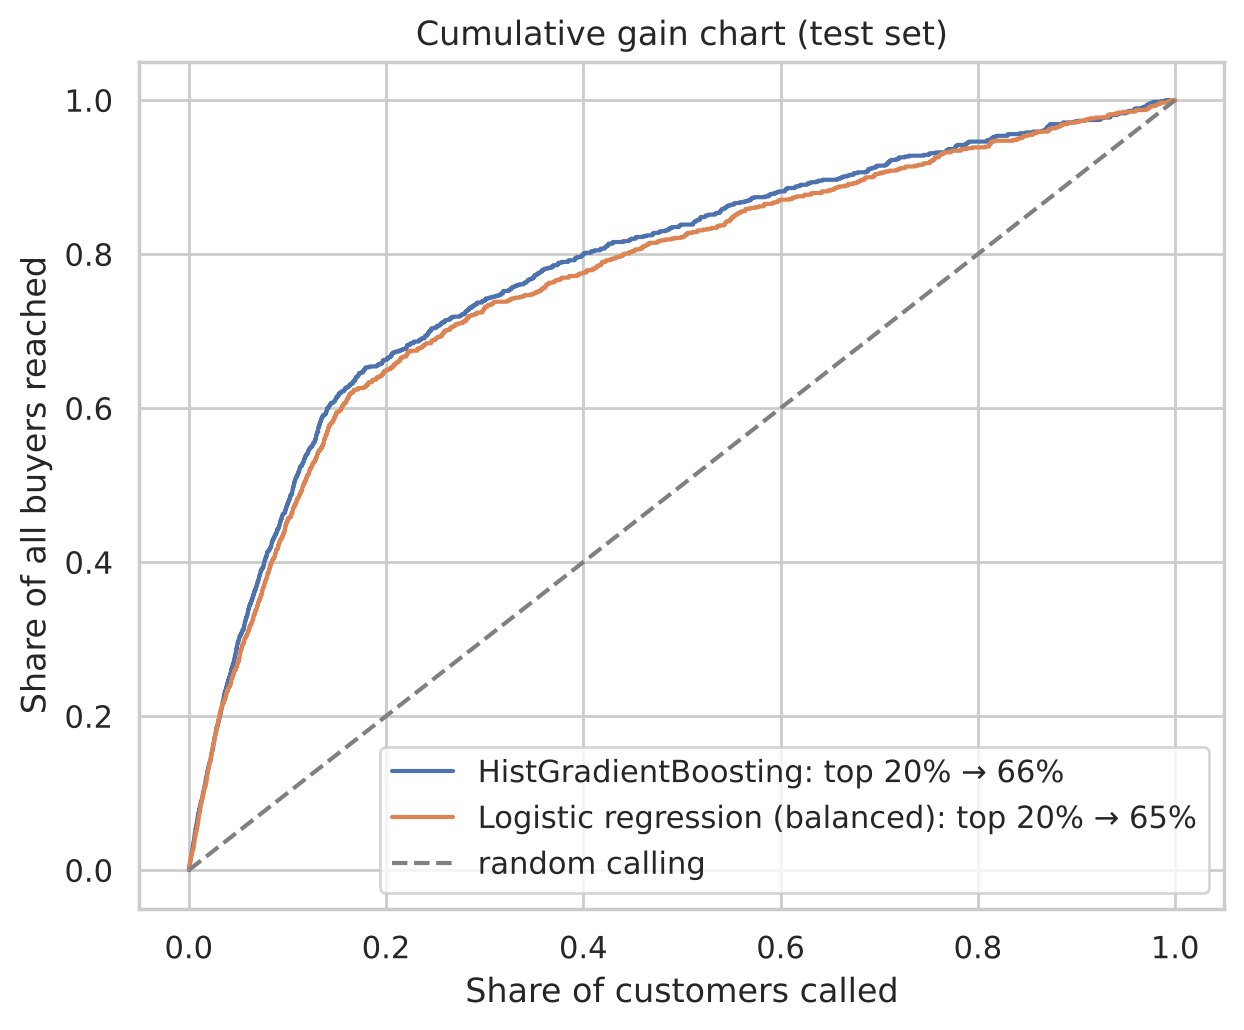

In [4]:
logreg = make_pipeline_for(X_tr, LogisticRegression(class_weight="balanced", max_iter=2000)).fit(X_tr, y_tr)

plt.figure(figsize=(7, 5.5))
for name, scores in [("HistGradientBoosting", test_proba), ("Logistic regression (balanced)", logreg.predict_proba(X_te)[:, 1])]:
    order = np.argsort(-scores)
    gain_curve = np.cumsum(y_te.values[order]) / y_te.sum()
    share = np.arange(1, len(y_te) + 1) / len(y_te)
    plt.plot(share, gain_curve, label=f"{name}: top 20% → {gain_curve[int(0.2 * len(y_te)) - 1]:.0%}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="random calling")
plt.xlabel("Share of customers called")
plt.ylabel("Share of all buyers reached")
plt.legend(loc="lower right")
plt.title("Cumulative gain chart (test set)")
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

دو منحنی بسیار نزدیک‌اند و HistGradientBoosting کمی بالاتر است. نکته: `class_weight="balanced"` احتمال‌ها را جابه‌جا می‌کند (همه بزرگ‌تر می‌شوند)، ولی **ترتیب** مشتریان را تقریباً تغییر نمی‌دهد؛ نمودار بهره فقط به ترتیب وابسته است. اگر از این مدل برای تصمیم بر اساس سود استفاده کنیم، باید آستانه را دوباره تنظیم کنیم، چون احتمال‌هایش دیگر احتمال واقعی نیستند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### تمرین ۴

ستون‌های شاخص اقتصادی را حذف کنید و مدل را دوباره ارزیابی کنید. Average Precision چقدر افت می‌کند؟ این نتیجه دربارهٔ استفاده از مدل در شرایط اقتصادی جدید چه می‌گوید؟

</div>

In [5]:
econ = ["emp_var_rate", "cons_price_idx", "cons_conf_idx", "euribor3m", "nr_employed"]
for label, drop in [("all features", ["duration"]), ("without economic indicators", ["duration"] + econ)]:
    X_a, _, y_a, _ = split(drop)
    scores = cross_val_score(make_pipeline_for(X_a, hgb()), X_a, y_a, cv=cv, scoring="average_precision", n_jobs=-1)
    print(f"{label:<28} CV average precision = {scores.mean():.3f}")

all features                 CV average precision = 0.469


without economic indicators  CV average precision = 0.414


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

بدون شاخص‌های اقتصادی، Average Precision به‌طور قابل توجهی افت می‌کند؛ یعنی بخش بزرگی از قدرت مدل از **وضعیت اقتصاد در زمان تماس** می‌آید، نه از ویژگی‌های مشتری. این یک هشدار مهم برای استقرار است: مدل روی دادهٔ سال‌های ۲۰۰۸ تا ۲۰۱۰ و شرایط اقتصادی آن دوره آموزش دیده است. اگر شرایط اقتصادی به محدوده‌ای برود که در دادهٔ آموزش نبوده، پیش‌بینی‌ها قابل اعتماد نیستند. باید عملکرد مدل را بعد از استقرار **پایش** کرد و با دادهٔ جدید دوباره آموزش داد.

</div>